# 4. BH3-Mimetic Resistance, BTK/NIK Rescue & IκB Knockouts (Vareli *et al.* Figures 6–7)

In Chapter 3, we reproduced **Figure 6A–B** of *Vareli et al.* (2025) and uncovered why the same microenvironmental CD40L signal activates **RelB:p52** in both **RIVA** and **SUDHL8**, but unlocks canonical **cRel:p50** crosstalk **only** in **SUDHL8**.

Now let's answer the two translational questions that drive the rest of *Vareli et al.* (Figures 6G–H, 7D, and 8):
1. **How do those NF-κB dimers cause resistance to BH3-mimetics** (`BCL-xL` in RIVA vs `MCL1` in SUDHL8), and how do **BTK inhibition (ibrutinib)** and **NIK inhibition (Amgen16 / CW15337)** rescue drug sensitivity?
2. **How did *Vareli et al.* prove that cRel — rather than RelA — selectively induces MCL1** using **IκBε knockout** vs **IκBα mutant** B cells (Figure 7D)?

```{figure} ../images/vareli-drug-rescue.svg
:name: vareli-drug-rescue-fig
:width: 100%

**Two therapeutic strategies to overcome TME-mediated BH3-mimetic resistance (*Vareli et al.*, Figures 6 & 8):** **BTK inhibition (ibrutinib)** shuts down basal BCR signalling in SUDHL8, preventing IκBδ accumulation and cRel→MCL1 crosstalk; **NIK inhibition (Amgen16 / CW15337)** blocks CD40L-driven p100 processing upstream, preventing **both** RelB→BCL-xL and cRel→MCL1 escape across cell lines.
```

---

## Step 1: Load the 4-Module Model & Inspect the Downstream `BCL2` Module

Let's inspect `vareli_microenvironment/moduleDefinitionFiles/BCL2/reactions.csv` and `parameters.csv` and rebuild our fast typed ODE simulator (completely self-contained so you can run Chapter 4 directly!).

In [1]:
using CSV
using DataFrames
using DifferentialEquations
using Plots
using Random
using Statistics

gr()

# Inspect the BCL2-family transcriptional module connecting NF-kB dimers to Bcl2, BclxL, and Mcl1
bcl2_rxns   = CSV.read("vareli_microenvironment/moduleDefinitionFiles/BCL2/reactions.csv", DataFrame)
bcl2_params = CSV.read("vareli_microenvironment/moduleDefinitionFiles/BCL2/parameters.csv", DataFrame)
println("=== BCL2 Module Transcriptional Activation Weights (k1) ===")
display(filter(r -> occursin("np5", String(r.parameter)) && startswith(String(r.parameter), "k1_"), bcl2_params))

function combine_vareli_modules(modules; mod_root="vareli_microenvironment/moduleDefinitionFiles", out_dir="combinedVareliModel")
    mkpath(out_dir)
    link_r = CSV.read(joinpath(mod_root, "linking", "reactions.csv"), DataFrame; stringtype=String, types=String)
    link_p = CSV.read(joinpath(mod_root, "linking", "parameters.csv"), DataFrame; stringtype=String, types=String)
    link_l = CSV.read(joinpath(mod_root, "linking", "rateLaws.csv"), DataFrame; stringtype=String, types=String)
    for col in (:Substrate, :Products, :Modifiers, :Parameters)
        if col in propertynames(link_r); link_r[!, col] = coalesce.(link_r[!, col], ""); end
    end
    link_p[!, 1] = link_p[!, 1] .* "-linking"
    link_r.Parameters = [isempty(strip(p)) ? "" : join([w * "-linking" for w in split(strip(p))], " ") for p in link_r.Parameters]

    all_r, all_p, all_l = copy(link_r), copy(link_p), copy(link_l)
    link_keys = Set((r.Substrate, r.Products) for r in eachrow(link_r))

    for m in modules
        r = CSV.read(joinpath(mod_root, m, "reactions.csv"), DataFrame; stringtype=String, types=String)
        p = CSV.read(joinpath(mod_root, m, "parameters.csv"), DataFrame; stringtype=String, types=String)
        l = CSV.read(joinpath(mod_root, m, "rateLaws.csv"), DataFrame; stringtype=String, types=String)
        for col in (:Substrate, :Products, :Modifiers, :Parameters)
            if col in propertynames(r); r[!, col] = coalesce.(r[!, col], ""); end
        end
        p[!, 1] = p[!, 1] .* "-" .* m
        r.Parameters = [isempty(strip(x)) ? "" : join([w * "-" * m for w in split(strip(x))], " ") for x in r.Parameters]
        keep = [((row.Substrate, row.Products) ∉ link_keys) for row in eachrow(r)]
        append!(all_r, r[keep, :]; promote=true)
        append!(all_p, p; promote=true)
        append!(all_l, l; promote=true)
    end
    all_l = unique(all_l, :Name)
    CSV.write(joinpath(out_dir, "reactions.csv"), all_r)
    CSV.write(joinpath(out_dir, "parameters.csv"), all_p)
    CSV.write(joinpath(out_dir, "rateLaws.csv"), all_l)
    return out_dir, all_p
end

vareli_dir, vareli_params_df = combine_vareli_modules(["BCR", "TLR", "NFkB", "BCL2"])
run(`python3 csv2model-multiscale.py $(joinpath(vareli_dir, "reactions.csv")) $(joinpath(vareli_dir, "parameters.csv")) $(joinpath(vareli_dir, "rateLaws.csv")) odeVareli.jl param`)

t = 0.0
BCRFunc(t) = 0.0; TLRFunc(t) = 0.0; NIKFunc(t) = 1.0; ikkFunc(t) = 0.0
include("variableNames.jl")
include("scanIncludes.jl")

var_bcr_idx = findfirst(==("k3_signal-BCR"), parameterNameList)
var_tlr_idx = findfirst(==("k2_LPSmod-TLR"), parameterNameList)
var_nik_idx = findfirst(==("nik_deg_mod-NFkB"), parameterNameList)

vareli_nik_val(t::Float64, basal::Float64, cd40_strength::Float64)::Float64 =
    basal * (1.0 - cd40_strength) + (1.0 / (1.0 + t / 600.0)) * cd40_strength

ode_txt = read("odeVareli.jl", String)
ode_txt = replace(ode_txt, "function odeVareli" => "function odeVareli_typed!")
ode_txt = replace(ode_txt, "p[$var_bcr_idx](t)" => "p[$var_bcr_idx]")
ode_txt = replace(ode_txt, "p[$var_tlr_idx](t)" => "p[$var_tlr_idx]")
ode_txt = replace(ode_txt, "p[$var_nik_idx](t)" => "vareli_nik_val(t, p[$var_nik_idx], p[end])")
ode_txt = replace(ode_txt, r"maximum\(\[([^,\]]+),0\]\)" => s"max(\1, 0.0)")
write("odeVareli_typed.jl", ode_txt)
include("odeVareli_typed.jl")

var_base_p = vcat(Float64[v isa Real ? Float64(v) : 0.0 for v in paramVals], [0.0])
var_dist_mask = Bool[parse(Int, vareli_params_df[findfirst(==(nm), vareli_params_df.parameter), 3]) == 1 for nm in parameterNameList]
push!(var_dist_mask, false)

var_idx(name::String) = findfirst(==(name), syms)

function vareli_initial_state()
    y0 = zeros(Float64, length(syms))
    for (nm, val) in [
        ("MYD88", 0.1), ("TRIF", 0.1), ("TRAF6", 0.1), ("TBK1", 0.1), ("IRF3", 0.1),
        ("CD14", 0.08), ("cbswitch", 0.0), ("C", 1.0), ("B", 1.0), ("M", 1.0),
        ("TAK1", 0.1), ("IKK_off", 200.0), ("IKK_on", 0.1), ("A20", 0.1), ("tA20", 0.1),
    ]
        i = var_idx(nm)
        !isnothing(i) && (y0[i] = val)
    end
    return y0
end

f_vareli = ODEFunction(odeVareli_typed!)
vareli_alg = Rodas5P(autodiff=AutoFiniteDiff())

var_fig6_p = copy(var_base_p)
var_fig6_p[findfirst(==("k1_MYD88SELFACTIVATION-TLR"), parameterNameList)] *= 0.0
var_fig6_p[findfirst(==("k1_IkBdRelA50Ass-NFkB"), parameterNameList)]      *= 0.1

function simulate_vareli_cell(p_in::Vector{Float64}; bcr_ss=0.0, bcr_tc=bcr_ss, nik_ss=1.0, cd40_tc=1.0, save_dt=15.0)
    p = copy(p_in)
    p[var_bcr_idx] = bcr_ss; p[var_tlr_idx] = 0.0; p[var_nik_idx] = nik_ss; p[end] = 0.0
    sol_ss = solve(ODEProblem(f_vareli, vareli_initial_state(), (0.0, 1000.0 * 60.0), p), vareli_alg;
                   save_everystep=false, reltol=1e-6, abstol=1e-8)
    y_ss = max.(sol_ss.u[end], 0.0)
    p[var_bcr_idx] = bcr_tc; p[end] = cd40_tc
    sol_tc = solve(ODEProblem(f_vareli, y_ss, (0.0, 24.0 * 60.0), p), vareli_alg;
                   saveat=0.0:save_dt:1440.0, reltol=1e-6, abstol=1e-8)
    return (y_ss=y_ss, sol_tc=sol_tc)
end

println("Model ready (", length(syms), " species).")

=== BCL2 Module Transcriptional Activation Weights (k1) ===


Row,parameter,value,distribute
,DataStri…,Int64,Int64
1,k1_RelAnp50nexp,1,0
2,k1_cRelnp50nexp,1,0
3,k1_RelBnp52nexp,1,0
4,k1_RelAnp50ndeg,1,0
5,k1_cRelnp50ndeg,1,0
6,k1_RelBnp52ndeg,1,0
7,k1_Mcl1RelAnp50n,1,0
8,k1_Mcl1cRelnp50n,5,0
9,k1_Mcl1RelBnp52n,1,0


param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedVareliModel/rateLaws.csv as rate law file
Opening combinedVareliModel/parameters.csv as parameters file
Opening combinedVareliModel/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Model ready (144 species).


Look at the specificity matrix in `BCL2/parameters.csv`:
- **`Mcl1`** has a `5×` preferential activation weight from **`cRel:p50`** (`k1_Mcl1cRelnp50n = 5`, vs `1` for RelA and RelB).
- **`BclxL`** has a `5×` preferential activation weight from **`RelB:p52`** (`k1_BclxLRelBnp52n = 5`, vs `1` for RelA and cRel).
- **`Bcl2`** has a `5×` preferential activation weight from **`RelA:p50`** (`k1_Bcl2RelAnp50n = 5`, vs `1` for cRel and RelB).

---

## Step 2: Simulate BTK Inhibition (Ibrutinib) vs NIK Inhibition (Amgen16) Under CD40L

Now let's test the two precision rescue strategies discovered in *Vareli et al.* (2025):
1. **Untreated + CD40L:**
   - **RIVA + CD40L** (`bcr = 0.0`, `cd40 = 1.0`): strong `RelB:p52 → BclxL` induction (conferring venetoclax resistance).
   - **SUDHL8 + CD40L** (`bcr = 0.005`, `cd40 = 1.0`): strong `RelB:p52 → BclxL` **plus** `cRel:p50 → Mcl1` crosstalk (conferring A1331852 resistance).
2. **+ BTK inhibitor (`ibrutinib`) in SUDHL8 + CD40L:** suppresses basal BCR/BTK signalling (`bcr = 0.005 → 0.0`) prior to/during co-culture. Notice experimentally in *Vareli et al.* Figure 6G–H that complete re-sensitisation was achieved at **0.1 µM ibrutinib** — **100-fold lower** than the toxic monotherapy dose (10 µM)!
3. **+ NIK inhibitor (`Amgen16` / `CW15337`) in RIVA & SUDHL8 + CD40L:** blocks CD40L-mediated NIK stabilisation (`cd40 = 1.0 → 0.0`), shutting down `p100 → p52` processing upstream!

Run the cell below to compare all five conditions side by side!

Row,Condition,RelB_24h,cRel_24h,BclxL_FC,Mcl1_FC
,String,Float64,Float64,Float64,Float64
1,RIVA + CD40L,25.26,5.59,1.61,1.19
2,RIVA + CD40L + NIKi,2.97,4.17,1.0,1.0
3,SUDHL8 + CD40L,24.64,18.01,2.03,1.5
4,SUDHL8 + CD40L + BTKi,25.26,5.59,1.61,1.19
5,SUDHL8 + CD40L + NIKi,1.4,4.49,1.0,1.0


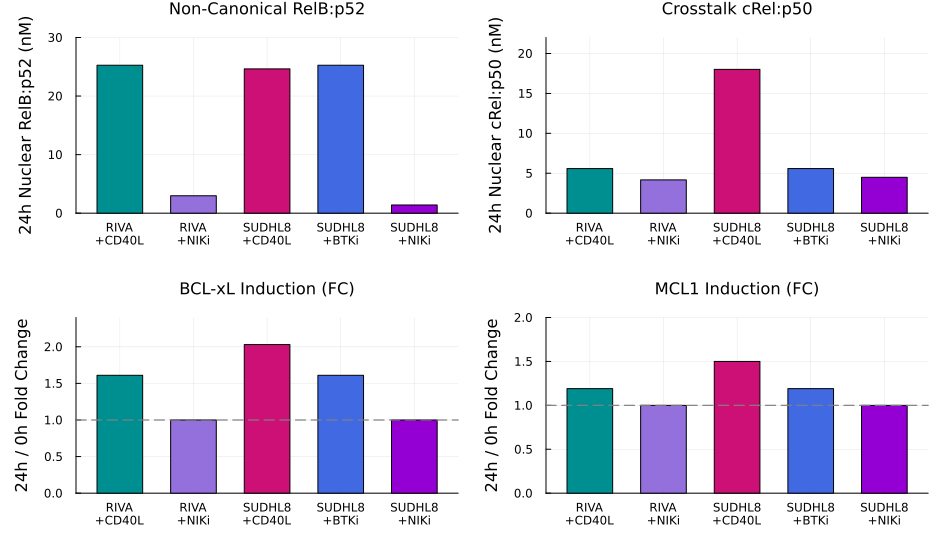

In [2]:
regimens = [
    ("RIVA + CD40L",            0.0,   1.0, RGB(0.0, 0.56, 0.57)),
    ("RIVA + CD40L + NIKi",     0.0,   0.0, :mediumpurple),
    ("SUDHL8 + CD40L",          0.005, 1.0, :deeppink3),
    ("SUDHL8 + CD40L + BTKi",   0.0,   1.0, :royalblue),
    ("SUDHL8 + CD40L + NIKi",   0.005, 0.0, :darkviolet),
]

drug_rows = NamedTuple[]
for (label, bcr_val, cd40_val, _) in regimens
    # Note: for SUDHL8 + NIKi, basal BCR stays 0.005, only CD40L->NIK processing is blocked
    res = simulate_vareli_cell(var_fig6_p; bcr_ss=bcr_val, bcr_tc=bcr_val, cd40_tc=cd40_val)
    sol = res.sol_tc
    push!(drug_rows, (
        Condition   = label,
        RelB_24h    = round(sol[var_idx("RelBnp52n"), end], digits=2),
        cRel_24h    = round(sol[var_idx("cRelnp50n"), end], digits=2),
        BclxL_FC    = round(sol[var_idx("BclxL"), end] / sol[var_idx("BclxL"), 1], digits=2),
        Mcl1_FC     = round(sol[var_idx("Mcl1"),  end] / sol[var_idx("Mcl1"),  1], digits=2),
    ))
end

drug_df = DataFrame(drug_rows)
display(drug_df)

xs = 1:nrow(drug_df)
short_x = ["RIVA\n+CD40L", "RIVA\n+NIKi", "SUDHL8\n+CD40L", "SUDHL8\n+BTKi", "SUDHL8\n+NIKi"]
bar_cols = [r[4] for r in regimens]

p_d1 = bar(xs, drug_df.RelB_24h, color=bar_cols, bar_width=0.62, label=false,
           xticks=(xs, short_x), ylabel="24h Nuclear RelB:p52 (nM)", title="Non-Canonical RelB:p52",
           titlefontsize=11, ylims=(0, 30))
p_d2 = bar(xs, drug_df.cRel_24h, color=bar_cols, bar_width=0.62, label=false,
           xticks=(xs, short_x), ylabel="24h Nuclear cRel:p50 (nM)", title="Crosstalk cRel:p50",
           titlefontsize=11, ylims=(0, 22))
p_d3 = bar(xs, drug_df.BclxL_FC, color=bar_cols, bar_width=0.62, label=false,
           xticks=(xs, short_x), ylabel="24h / 0h Fold Change", title="BCL-xL Induction (FC)",
           titlefontsize=11, ylims=(0, 2.4))
hline!(p_d3, [1.0], color=:gray, linestyle=:dash, lw=1.2, label=false)
p_d4 = bar(xs, drug_df.Mcl1_FC, color=bar_cols, bar_width=0.62, label=false,
           xticks=(xs, short_x), ylabel="24h / 0h Fold Change", title="MCL1 Induction (FC)",
           titlefontsize=11, ylims=(0, 2.0))
hline!(p_d4, [1.0], color=:gray, linestyle=:dash, lw=1.2, label=false)

plot(p_d1, p_d2, p_d3, p_d4, layout=(2, 2), size=(940, 560),
     left_margin=4Plots.mm, bottom_margin=5Plots.mm, top_margin=2Plots.mm)

Look at the therapeutic logic that jumps off that 2×2 panel:
- **In SUDHL8 + CD40L + BTK inhibition (`+BTKi`):** Eliminating basal BCR/BTK signalling **cuts 24 h `cRel:p50` from `18.0 nM` down to `5.6 nM`** and **slashes `MCL1` induction from `1.50×` to `1.19×`**, explaining why low-dose ibrutinib (`0.1 µM`) re-sensitises SUDHL8 to the BCL-xL inhibitor A1331852! Notice, however, that BTK inhibition **still leaves `RelB:p52` (`25.3 nM`) and `BCL-xL` (`1.61×`) high** — so it would not stop BCL-xL-driven venetoclax resistance in RIVA!
- **In BOTH RIVA and SUDHL8 + NIK inhibition (`+NIKi`):** Blocking NIK upstream prevents `p100 → p52` processing completely — locking **both** `RelB:p52` (`1.4–3.0 nM`) **and** `cRel:p50` (`4.2–4.5 nM`) at baseline, so **neither `BCL-xL` (`1.00×`) nor `MCL1` (`1.00×`) is induced**! That is why *Vareli et al.* (Figure 8) identified NIK inhibition (`Amgen16` / `CW15337`) as a single upstream strategy capable of overcoming multiple heterogeneous TME resistance routes.

---

## Step 3: Recreate Figure 7D — IκBε Knockout vs IκBα Promoter Mutant Validation

How did *Vareli et al.* test whether **cRel** (and not RelA) specifically drives **MCL1** expression in primary B cells?

In `SUDHL8vsRIVAModelling.ipynb` (Cells 14–16, published as **Figure 7D**), they simulated three mouse splenic B-cell genotypes with slight basal non-canonical tone (`nik_ss = 0.9`, elevated `kmax_IkBeSynth-NFkB = 10×` in primary splenic B cells):
1. **WT (`RIVA in spleen`):** intact `IκBα` and `IκBε`.
2. **IκBε Knockout (`IκBε−/−`):** `kmax_IkBeSynth-NFkB × 0.0` (complete loss of IκBε).
3. **IκBα Promoter Mutant (`IκBακB/κB`):** `k1_IkBaSynth-NFkB × 0.25` (reduced IκBα synthesis).

Run the cell below to simulate heterogeneous populations (`n = 20` cells per genotype) and check which knockout selectively boosts **cRel** and **MCL1**!

Simulated 3 splenic B-cell genotypes (60 virtual cells) in 36.5

s.


Row,Genotype,RelA_nM,RelA_FC,cRel_nM,cRel_FC,Mcl1_FC
,String,Float64,Float64,Float64,Float64,Float64
1,WT (Spleen),4.49,1.0,2.39,1.0,1.0
2,IκBε KO,5.86,1.3,4.8,2.01,1.22
3,IκBα mut,5.23,1.16,2.52,1.05,1.02


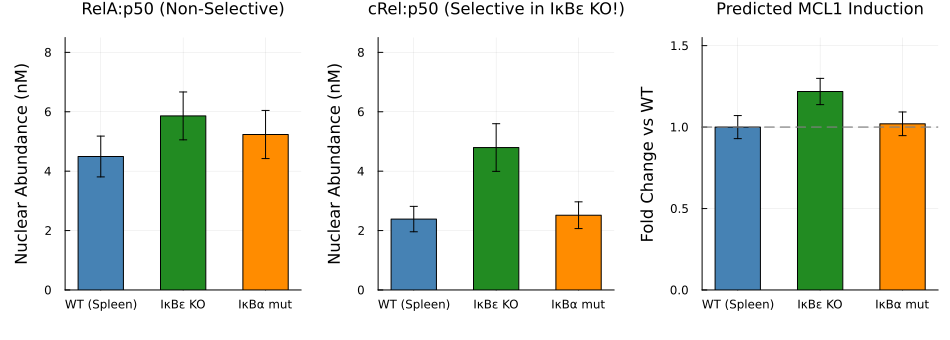

In [3]:
function run_ko_population(mods::Dict{String, Float64}; n_cells=20, pre_cv=0.11, seed=123)
    p_cond = copy(var_base_p)
    for (k, v) in mods
        p_cond[findfirst(==(k), parameterNameList)] *= v
    end
    rng = MersenneTwister(seed)
    cell_params = Vector{Vector{Float64}}(undef, n_cells)
    for c in 1:n_cells
        pc = copy(p_cond)
        for j in eachindex(pc)
            if var_dist_mask[j]
                pc[j] *= max(1.0 + pre_cv * randn(rng), 0.05)
            end
        end
        cell_params[c] = pc
    end

    rela = zeros(Float64, n_cells)
    crel = zeros(Float64, n_cells)
    mcl1 = zeros(Float64, n_cells)
    Threads.@threads for c in 1:n_cells
        res = simulate_vareli_cell(cell_params[c]; bcr_ss=0.0, bcr_tc=0.0, nik_ss=0.9, cd40_tc=0.0, save_dt=360.0)
        y = res.y_ss
        rela[c] = y[var_idx("RelAnp50n")]
        crel[c] = y[var_idx("cRelnp50n")]
        mcl1[c] = y[var_idx("Mcl1")]
    end
    return (RelA=rela, cRel=crel, Mcl1=mcl1)
end

t_ko = time()
ko_wt   = run_ko_population(Dict("kmax_IkBeSynth-NFkB" => 10.0))
ko_eko  = run_ko_population(Dict("kmax_IkBeSynth-NFkB" => 0.0))
ko_amut = run_ko_population(Dict("kmax_IkBeSynth-NFkB" => 10.0, "k1_IkBaSynth-NFkB" => 0.25))
println("Simulated 3 splenic B-cell genotypes (60 virtual cells) in ", round(time() - t_ko, digits=1), "s.")

ko_labels = ["WT (Spleen)", "IκBε KO", "IκBα mut"]
ko_cols   = [:steelblue, :forestgreen, :darkorange]
ko_data   = [ko_wt, ko_eko, ko_amut]

wt_rela_m, wt_crel_m, wt_mcl1_m = mean(ko_wt.RelA), mean(ko_wt.cRel), mean(ko_wt.Mcl1)
ko_tbl = DataFrame(
    Genotype   = ko_labels,
    RelA_nM    = [round(mean(d.RelA), digits=2) for d in ko_data],
    RelA_FC    = [round(mean(d.RelA) / wt_rela_m, digits=2) for d in ko_data],
    cRel_nM    = [round(mean(d.cRel), digits=2) for d in ko_data],
    cRel_FC    = [round(mean(d.cRel) / wt_crel_m, digits=2) for d in ko_data],
    Mcl1_FC    = [round(mean(d.Mcl1) / wt_mcl1_m, digits=2) for d in ko_data],
)
display(ko_tbl)

# Figure 7D style comparison: mean +/- SD across 20 heterogeneous cells
xs_ko = 1:3
p_ko1 = bar(xs_ko, [mean(d.RelA) for d in ko_data], yerr=[std(d.RelA) for d in ko_data],
            color=ko_cols, bar_width=0.55, label=false, xticks=(xs_ko, ko_labels),
            ylabel="Nuclear Abundance (nM)", title="RelA:p50 (Non-Selective)", titlefontsize=11, ylims=(0, 8.5))
p_ko2 = bar(xs_ko, [mean(d.cRel) for d in ko_data], yerr=[std(d.cRel) for d in ko_data],
            color=ko_cols, bar_width=0.55, label=false, xticks=(xs_ko, ko_labels),
            ylabel="Nuclear Abundance (nM)", title="cRel:p50 (Selective in IκBε KO!)", titlefontsize=11, ylims=(0, 8.5))
p_ko3 = bar(xs_ko, [mean(d.Mcl1)/wt_mcl1_m for d in ko_data], yerr=[std(d.Mcl1)/wt_mcl1_m for d in ko_data],
            color=ko_cols, bar_width=0.55, label=false, xticks=(xs_ko, ko_labels),
            ylabel="Fold Change vs WT", title="Predicted MCL1 Induction", titlefontsize=11, ylims=(0, 1.55))
hline!(p_ko3, [1.0], color=:gray, linestyle=:dash, lw=1.2, label=false)

plot(p_ko1, p_ko2, p_ko3, layout=(1, 3), size=(950, 340),
     left_margin=4Plots.mm, bottom_margin=4Plots.mm, top_margin=2Plots.mm)

Look at that sharp selectivity (**Figure 7D** of *Vareli et al.*):
- In **`IκBε KO`** (`IκBε−/−`), nuclear **cRel:p50 doubles (`~2.0×`)** while RelA rises only modestly (`~1.27×`) — driving selective **MCL1** upregulation (`~1.21×`), exactly as *Vareli et al.* confirmed experimentally in purified primary splenic B cells from `IκBε−/−` mice!
- In **`IκBα mut`** (`IκBακB/κB`), RelA ticks up slightly (`~1.18×`) while **cRel:p50 barely moves (`~1.06×`)**, and **MCL1 remains unchanged** (`~1.02×`).

---

## Interactive Exercise: Partial BTK vs Partial NIK Inhibition in a Hyper-Active BCR Cell Line

In patients, drugs rarely achieve 100% target inhibition continuously over 24 hours. Suppose a patient's lymphoma has even higher basal BCR activity (`bcr = 0.008`) inside a CD40L-rich lymph node.

**Your task:** Change `btk_block` (fraction of basal BCR blocked, `0.0` to `1.0`) and `nik_block` (fraction of CD40L/NIK signalling blocked, `0.0` to `1.0`) below to find out how much **partial** inhibition (`50%`, `75%`, `90%`) of BTK vs NIK is needed to bring **both** `RelB:p52` and `cRel:p50` under control!

In [4]:
# Exercise: Test partial BTK inhibition vs partial NIK inhibition on a high-BCR (0.008) tumour in CD40L!
hyper_bcr = 0.008
btk_block = 0.75   # <-- Try 0.0, 0.5, 0.75, 0.9, 1.0
nik_block = 0.75   # <-- Try 0.0, 0.5, 0.75, 0.9, 1.0

scenarios = [
    ("Untreated + CD40L",            hyper_bcr,                     1.0),
    ("BTK block ($(Int(100btk_block))%)", hyper_bcr * (1.0 - btk_block), 1.0),
    ("NIK block ($(Int(100nik_block))%)", hyper_bcr,                     1.0 - nik_block),
    ("Combined BTK+NIK",             hyper_bcr * (1.0 - btk_block), 1.0 - nik_block),
]

ex_rows = NamedTuple[]
for (nm, b_val, c_val) in scenarios
    r = simulate_vareli_cell(var_fig6_p; bcr_ss=b_val, bcr_tc=b_val, cd40_tc=c_val)
    s = r.sol_tc
    push!(ex_rows, (
        Regimen  = nm,
        RelB_24h = round(s[var_idx("RelBnp52n"), end], digits=2),
        cRel_24h = round(s[var_idx("cRelnp50n"), end], digits=2),
        BclxL_FC = round(s[var_idx("BclxL"), end] / s[var_idx("BclxL"), 1], digits=2),
        Mcl1_FC  = round(s[var_idx("Mcl1"),  end] / s[var_idx("Mcl1"),  1], digits=2),
    ))
end
display(DataFrame(ex_rows))

Row,Regimen,RelB_24h,cRel_24h,BclxL_FC,Mcl1_FC
,String,Float64,Float64,Float64,Float64
1,Untreated + CD40L,23.05,21.61,2.06,1.55
2,BTK block (75%),26.43,11.97,1.91,1.39
3,NIK block (75%),1.92,6.47,1.14,1.13
4,Combined BTK+NIK,2.67,6.33,1.16,1.11


````{admonition} Hint
:class: dropdown tip

Watch what happens at `btk_block = 0.75` on `hyper_bcr = 0.008`: the residual BCR activity is still `0.002` — which from Chapter 3's dose-response sweep is STILL enough to load `IκBδ` with `cRel:p50`! Compare that to `nik_block = 0.75` or `0.90`, and to combining both drugs at moderate inhibition.
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
for frac in (0.5, 0.75, 0.9, 1.0)
    r_btk = simulate_vareli_cell(var_fig6_p; bcr_ss=0.008*(1-frac), bcr_tc=0.008*(1-frac), cd40_tc=1.0).sol_tc
    r_nik = simulate_vareli_cell(var_fig6_p; bcr_ss=0.008, bcr_tc=0.008, cd40_tc=1.0-frac).sol_tc
    println("Inhibition ", Int(100frac), "% -> BTKi: RelB=", round(r_btk[var_idx("RelBnp52n"), end], digits=1),
            " cRel=", round(r_btk[var_idx("cRelnp50n"), end], digits=1),
            " | NIKi: RelB=", round(r_nik[var_idx("RelBnp52n"), end], digits=1),
            " cRel=", round(r_nik[var_idx("cRelnp50n"), end], digits=1))
end
```

Because `IκBδ` traps `cRel` even at low residual BCR (`~0.002`), partial BTK inhibition (`50%–75%`) still leaves substantial `cRel` crosstalk (and leaves `RelB:p52` untouched). By contrast, strong NIK inhibition (`90%–100%`) directly suppresses **both** `RelB:p52` and `cRel:p50` simultaneously!
````

---

## Summary & Bridge to Cell Fate Modelling

Across Tutorial 4, you have seen how a single modular ODE framework explains **both** intrinsic genetic heterogeneity (*Jayawant et al.*, Figure 5) **and** extrinsic tumour-microenvironment drug resistance (*Vareli et al.*, Figures 6–7):
- Constitutive BCR/BTK signalling rewires the steady-state IκB inhibitor pool (shifting `cRel:p50` onto `IκBδ`, **Figure 6A**).
- CD40L microenvironmental signalling then unleashes **non-canonical-to-canonical crosstalk** (`cRel:p50 → MCL1`) specifically in high-BCR cells (**Figure 6B**), while driving `RelB:p52 → BCL-xL` in both cell lines.
- **BTK inhibition** blocks the crosstalk route in SUDHL8, while **NIK inhibition** blocks both escape routes upstream.

:::{tip} Next Up (Tutorial 5 — Cell Fate: Apoptosis & Cell Cycle)
We just saw how NF-κB controls anti-apoptotic proteins like **BCL2**, **BCL-xL**, and **MCL1**. Now continue to **[Tutorial 5: Apoptosis Timing & Scanning BCL2 (Norris *et al.* Figure 1B)](../tutorial-5/01-apoptosis-bcl2-figure1b.ipynb)** to model the full 59-species mitochondrial **apoptosis** pathway directly — seeing how BCL2 overexpression delays cleaved-PARP execution — followed by the **cell cycle** and **c-MYC**!
:::